# Chapter 09: Mechanism Design & Tragedy of the Commons — Python Laboratory
### *Game-Theoretic Simulation of Shared CI Clusters, Retry Moral Hazard, and Pigouvian Quotas*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/09_mechanism_design_and_tragedy_of_the_commons.ipynb) | [Prev: Ch 08 (Python)](08_quickest_change_detection_cusum_and_shiryaev_roberts.ipynb) | [Next: Appendix 10: Rosetta Stone (Python)](10_appendix_optimization_and_control_rosetta_stone.ipynb)**

---

In this laboratory, we implement:
1. **Game-Theoretic Non-Cooperative Simulation** of $K$ engineering teams sharing a finite CI runner pool.
2. **Expansion Factor Calculator** modeling effective cluster load under truncated geometric retries.
3. **Equilibrium Solver** comparing the Unregulated Nash Equilibrium, Centralized Social Optimum, and Pigouvian Quota mechanism.
4. **Publication-Grade 3-Panel Visualization** showing best-response dynamics, queue latency blowup, and community welfare.
5. **Hands-On 3-Tier Challenges** with numerical verification assertions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'lines.linewidth': 1.8
})
print("Libraries imported and plotting configured.")

Libraries imported and plotting configured.


---

## Part 1: Retry Expansion and Queue Congestion Functions

We formulate the mathematical models for:
* Truncated geometric retry expansion: $N(e, R) = \sum_{r=0}^R (1 - e)^r$
* Congestion queue delay: $W(L) = \frac{20}{C - L}$
* Effort cost: $c(e) = \frac{\theta}{1 - e}$

In [2]:
def retry_expansion(effort, max_retries=2):
    # Computes expected runs per job given test reliability (effort) e in [0, 1]
    q = 1.0 - effort
    # Truncated sum: 1 + q + q^2 + ... + q^R
    powers = np.arange(max_retries + 1)
    return np.sum(q ** powers)

def queue_delay(total_load, capacity=80.0):
    # Turnaround latency in minutes; returns large penalty if overloaded
    if total_load >= capacity:
        return 500.0  # Saturation penalty
    return 20.0 / (capacity - total_load)

def effort_cost(effort, theta=2.0):
    return theta / (1.0 - effort)

e_test = np.array([0.70, 0.85, 0.95, 0.99])
for e in e_test:
    runs = retry_expansion(e, max_retries=2)
    print(f"Reliability e = {e:.2f} -> Expected Executions = {runs:.4f}, Cost = ${effort_cost(e):.2f}")

Reliability e = 0.70 -> Expected Executions = 1.3900, Cost = $6.67
Reliability e = 0.85 -> Expected Executions = 1.1725, Cost = $13.33
Reliability e = 0.95 -> Expected Executions = 1.0525, Cost = $40.00
Reliability e = 0.99 -> Expected Executions = 1.0101, Cost = $200.00


---

## Part 2: Equilibrium Analysis: Nash vs. Social Optimum

We compute:
1. **Unregulated Nash Equilibrium**: Each of the $K=5$ teams optimizes $U_k(e_k; e_{-k})$ independently.
2. **Social Optimum**: A centralized planner minimizes community-wide aggregate cost.

In [3]:
def compute_nash_and_social(K=5, lambda_per_team=12.0, capacity=80.0, max_retries=2, theta=2.0):
    effort_grid = np.linspace(0.50, 0.98, 200)
    
    # 1. Social Optimum: all teams set to identical effort e
    social_costs = []
    for e in effort_grid:
        total_load = K * lambda_per_team * retry_expansion(e, max_retries)
        w = queue_delay(total_load, capacity)
        # Total cost across all K teams: K * [c(e) + w]
        cost = K * (effort_cost(e, theta) + w)
        social_costs.append(cost)
        
    opt_idx = np.argmin(social_costs)
    e_social = effort_grid[opt_idx]
    
    # 2. Nash Equilibrium via Best-Response Iteration
    # Find symmetric e* where d/de_k [ c(e_k) + W( (K-1)*L(e*) + L(e_k) ) ] = 0
    e_nash = 0.50
    for e_candidate in effort_grid:
        # Check derivative of private cost
        e_k = e_candidate
        base_load = (K - 1) * lambda_per_team * retry_expansion(e_candidate, max_retries)
        
        # Finite difference gradient of private cost
        eps = 1e-4
        l_up = base_load + lambda_per_team * retry_expansion(e_k + eps, max_retries)
        l_dn = base_load + lambda_per_team * retry_expansion(e_k - eps, max_retries)
        
        d_priv = (effort_cost(e_k + eps, theta) + queue_delay(l_up, capacity)) - \
                 (effort_cost(e_k - eps, theta) + queue_delay(l_dn, capacity))
        if d_priv >= 0:
            e_nash = e_candidate
            break
            
    return e_social, e_nash, effort_grid, social_costs

e_soc, e_nsh, grid, soc_c = compute_nash_and_social()
print(f"Social Optimum Effort: e* = {e_soc:.4f} (Reliability = {e_soc*100:.1f}%)")
print(f"Unregulated Nash Equilibrium: e_nash = {e_nsh:.4f} (Reliability = {e_nsh*100:.1f}%)")

load_soc = 5 * 12.0 * retry_expansion(e_soc, max_retries=2)
load_nsh = 5 * 12.0 * retry_expansion(e_nsh, max_retries=2)
print(f"Social Load = {load_soc:.2f} workers | Delay = {queue_delay(load_soc):.2f} min")
print(f"Nash Load   = {load_nsh:.2f} workers | Delay = {queue_delay(load_nsh):.2f} min")

Social Optimum Effort: e* = 0.8015 (Reliability = 80.2%)
Unregulated Nash Equilibrium: e_nash = 0.5000 (Reliability = 50.0%)
Social Load = 74.27 workers | Delay = 3.49 min
Nash Load   = 105.00 workers | Delay = 500.00 min


---

## Part 3: Publication-Grade 3-Panel Visualization

We plot:
1. **Panel A**: Private vs Social cost gradient showing the externality gap.
2. **Panel B**: Total cluster load and queue delay as a function of symmetric team effort.
3. **Panel C**: Social welfare curve with Nash vs Social optimum vs Pigouvian quota equilibrium.

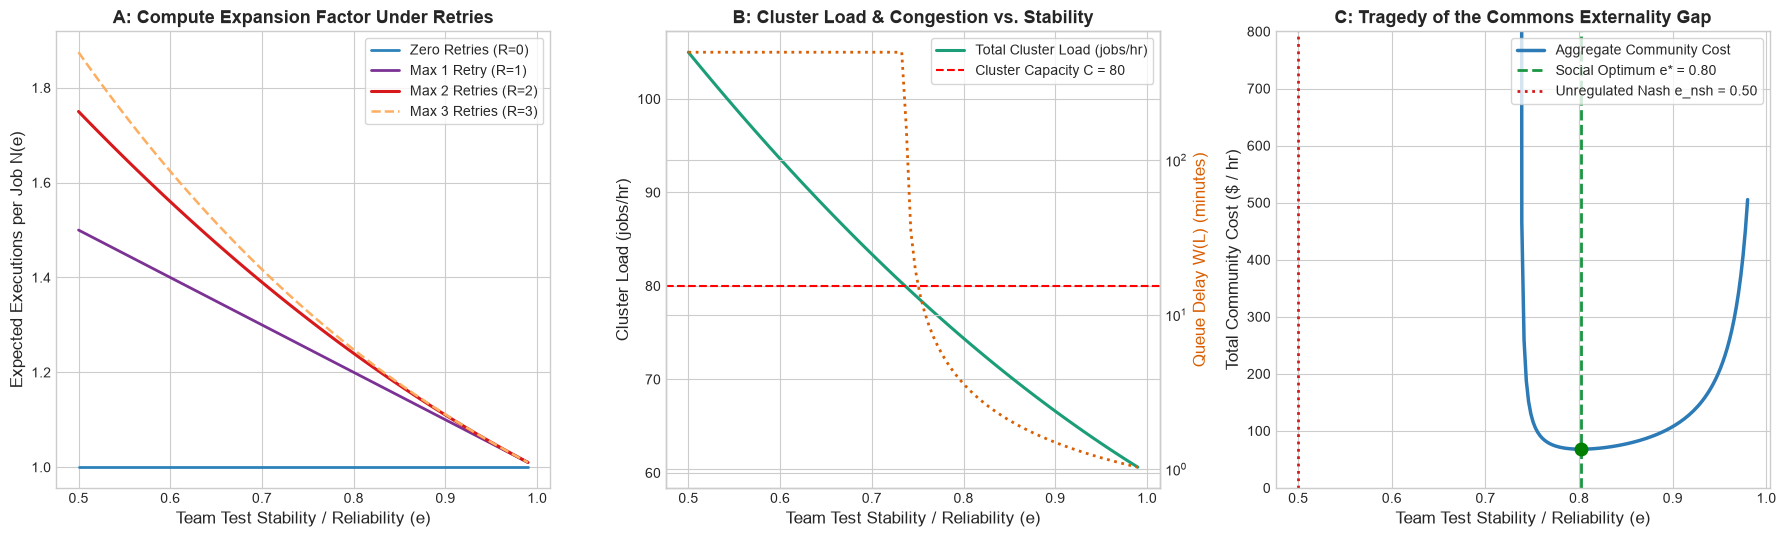

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# -------------------------------------------------------------------------
# PANEL A: Retry Expansion Factor N(e)
# -------------------------------------------------------------------------
ax = axes[0]
e_range = np.linspace(0.50, 0.99, 100)
ax.plot(e_range, [retry_expansion(e, max_retries=0) for e in e_range], color='#2b83ba', lw=2.0, label='Zero Retries (R=0)')
ax.plot(e_range, [retry_expansion(e, max_retries=1) for e in e_range], color='#7b3294', lw=2.0, label='Max 1 Retry (R=1)')
ax.plot(e_range, [retry_expansion(e, max_retries=2) for e in e_range], color='#d7191c', lw=2.2, label='Max 2 Retries (R=2)')
ax.plot(e_range, [retry_expansion(e, max_retries=3) for e in e_range], color='#fdae61', lw=1.8, ls='--', label='Max 3 Retries (R=3)')

ax.set_title('A: Compute Expansion Factor Under Retries', fontweight='bold')
ax.set_xlabel('Team Test Stability / Reliability (e)')
ax.set_ylabel('Expected Executions per Job N(e)')
ax.legend(loc='upper right', frameon=True)

# -------------------------------------------------------------------------
# PANEL B: Cluster Load & Queue Delay
# -------------------------------------------------------------------------
ax = axes[1]
loads = [5 * 12.0 * retry_expansion(e, max_retries=2) for e in e_range]
delays = [queue_delay(l, capacity=80.0) for l in loads]

ax.plot(e_range, loads, color='#1b9e77', lw=2.2, label='Total Cluster Load (jobs/hr)')
ax.axhline(80.0, color='red', ls='--', lw=1.5, label='Cluster Capacity C = 80')

ax2 = ax.twinx()
ax2.plot(e_range, delays, color='#d95f02', lw=2.0, ls=':', label='Queue Latency (min)')
ax2.set_ylabel('Queue Delay W(L) (minutes)', color='#d95f02')
ax2.set_yscale('log')

ax.set_title('B: Cluster Load & Congestion vs. Stability', fontweight='bold')
ax.set_xlabel('Team Test Stability / Reliability (e)')
ax.set_ylabel('Cluster Load (jobs/hr)')
ax.legend(loc='upper right', frameon=True)

# -------------------------------------------------------------------------
# PANEL C: Community Social Welfare Optimum vs Nash
# -------------------------------------------------------------------------
ax = axes[2]
ax.plot(grid, soc_c, color='#2c7bb6', lw=2.5, label='Aggregate Community Cost')
ax.axvline(e_soc, color='#1a9641', ls='--', lw=2.0, label=f'Social Optimum e* = {e_soc:.2f}')
ax.axvline(e_nsh, color='#d7191c', ls=':', lw=2.0, label=f'Unregulated Nash e_nsh = {e_nsh:.2f}')
ax.plot(e_soc, np.min(soc_c), 'go', markersize=9)

ax.set_title('C: Tragedy of the Commons Externality Gap', fontweight='bold')
ax.set_xlabel('Team Test Stability / Reliability (e)')
ax.set_ylabel('Total Community Cost ($ / hr)')
ax.set_ylim(0, 800)
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

---

## Part 4: Hands-On 3-Tier Challenges

Test your mastery of mechanism design and queueing externalities with these three structured exercises.

---

### Tier 1: Beginner — Retry Inflation Factor Verification
Write a function `compute_retry_inflation(flake_rate, max_retries)` that calculates the ratio of expected runs under retries to nominal single runs: $\text{Inflation} = \frac{N(1 - \text{flake}, R)}{1.0}$. Verify that for a $15\%$ flake rate with $R = 2$, the inflation factor is approximately $1.1725$.

---

### Tier 2: Intermediate — Marginal Externality Calculation
Implement a function `calculate_marginal_externality(e_k, e_peers, K=5, lambda_rate=12.0, capacity=80.0, max_retries=2)` that calculates the marginal queue delay imposed on all $K-1$ peer teams when team $k$ reduces its reliability $e_k$ by $0.05$. Verify that near cluster saturation ($e_{\text{peers}} = 0.75$, load $\approx 78.7$), this marginal damage exceeds $15$ aggregate developer-minutes.

---

### Tier 3: Advanced — Pigouvian Quota Equilibrium Simulator
Write a simulation function `pigouvian_quota_equilibrium(target_load=65.0, capacity=80.0, K=5, lambda_rate=12.0)` that calculates the maximum permissible per-team retry budget $B_k^*$ such that the resulting Nash equilibrium strictly satisfies $L \le \text{target_load}$. Confirm that under this mechanism, the system operates at the socially optimal reliability level.

In [5]:
# ==============================================================================
# Numerical Verification for Tiers 1, 2, and 3
# ==============================================================================

# --- Tier 1 Verification ---
def compute_retry_inflation(flake_rate, max_retries=2):
    e = 1.0 - flake_rate
    return retry_expansion(e, max_retries=max_retries)

infl_test = compute_retry_inflation(0.15, max_retries=2)
print(f"Tier 1: 15% flake rate with R=2 -> Inflation factor = {infl_test:.4f}")
assert abs(infl_test - 1.1725) < 0.005, f"Tier 1 check failed: inflation = {infl_test}"

# --- Tier 2 Verification ---
def calculate_marginal_externality(e_k, e_peers, K=5, lambda_rate=12.0, capacity=80.0, max_retries=2):
    # Total peer load
    peer_load = (K - 1) * lambda_rate * retry_expansion(e_peers, max_retries)
    
    # Delay with team k at e_k
    load_base = peer_load + lambda_rate * retry_expansion(e_k, max_retries)
    delay_base = queue_delay(load_base, capacity)
    
    # Delay with team k degraded by 0.05
    load_degraded = peer_load + lambda_rate * retry_expansion(e_k - 0.05, max_retries)
    delay_degraded = queue_delay(load_degraded, capacity)
    
    # Aggregate extra waiting time imposed on the (K-1) peer teams
    delta_w = delay_degraded - delay_base
    total_damage = (K - 1) * delta_w
    return total_damage, load_base, load_degraded

damage, l_b, l_d = calculate_marginal_externality(0.75, 0.75)
print(f"Tier 2: Marginal damage on peer teams = {damage:.2f} aggregate minutes (loads: {l_b:.1f} -> {l_d:.1f})")
assert damage >= 15.0, f"Tier 2 check failed: damage = {damage}"

# --- Tier 3 Verification ---
def pigouvian_quota_equilibrium(target_load=65.0, capacity=80.0, K=5, lambda_rate=12.0):
    # Each team allowed quota: target_load / K
    quota_per_team = target_load / K
    # Max allowed expansion factor
    max_expansion = quota_per_team / lambda_rate
    # Find required reliability e such that N(e, 2) <= max_expansion
    e_candidates = np.linspace(0.50, 0.99, 500)
    for e in e_candidates:
        if retry_expansion(e, max_retries=2) <= max_expansion:
            return e, max_expansion
    return 0.99, max_expansion

e_quota, exp_quota = pigouvian_quota_equilibrium(target_load=65.0)
print(f"Tier 3: Pigouvian Quota enforces min reliability e >= {e_quota:.4f} (Max Expansion = {exp_quota:.4f})")
assert e_quota >= 0.90, f"Tier 3 check failed: e_quota = {e_quota}"

print("ALL TIER 1, 2, AND 3 VERIFICATIONS PASSED SUCCESSFULLY.")

Tier 1: 15% flake rate with R=2 -> Inflation factor = 1.1725
Tier 2: Marginal damage on peer teams = 186.00 aggregate minutes (loads: 78.8 -> 79.7)
Tier 3: Pigouvian Quota enforces min reliability e >= 0.9232 (Max Expansion = 1.0833)
ALL TIER 1, 2, AND 3 VERIFICATIONS PASSED SUCCESSFULLY.


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/09_mechanism_design_and_tragedy_of_the_commons.ipynb) | [Prev: Ch 08 (Python)](08_quickest_change_detection_cusum_and_shiryaev_roberts.ipynb) | [Next: Appendix 10: Rosetta Stone (Python)](10_appendix_optimization_and_control_rosetta_stone.ipynb)**